# 3.2 Household groups: demand personas

**Question.** Which kinds of households look alike once electricity, gas, solar export, seasonality, evening peak and recent change are considered together, and do deprived groups form a persona of their own?

**Data.** SERL cleaned daily-statistics file (monthly rows) and the 2023 half-hourly file. The cleaned file is built by `python scripts/make_dataset.py` (see 3.1).

**Groups.** The same 75 household groups as 3.1 (`serl_energy.labels.household_groups`). A group is kept only if **every 2023 feature rests on at least 50 households**: SERL's PV export statistics shrink to a few dozen homes after 2021, so the PV group is dropped rather than described by a handful of homes.

| Feature | Definition (2023 unless stated) |
|---|---|
| electricity_kwh_per_day | mean daily electricity imports |
| gas_kwh_per_day | mean daily gas use |
| export_kwh_per_day | mean daily electricity exported (solar) |
| electricity_winter_extra | Dec–Feb minus Jun–Aug electricity, kWh/day |
| gas_winter_extra | Dec–Feb minus Jun–Aug gas, kWh/day |
| evening_share_pct | share of daily electricity imports between 16:00 and 19:00 (half-hourly profile) |
| change_since_2020_pct | % change in electricity imports, 2020 → 2023 |

Gas features use the available 2023 months when at least 9 of 12 are reported.

**Method.** Features are standardised and clustered with k-means (k = 2–7, the largest k within 0.01 of the best silhouette). Each persona is named after the two features that differ most from the average group.

**Outputs.** Figures in `reports/figures/3.2-household-personas/`, tables in `reports/tables/3.2-household-personas/`.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from serl_energy import dataset as serl, plots
from serl_energy.labels import household_groups, role
from serl_energy.plots import CATEGORICAL, COLORS, INK, ROLE_COLORS
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=UserWarning)
plots.use_theme()
reporter = Reporter("3.2-household-personas")

monthly_all = serl.load_monthly(serl.CLEAN_CSV)
monthly = monthly_all[monthly_all["unit"].eq("kWh/day") & monthly_all["weekday_weekend"].eq("both")]
hh = serl.load_half_hourly([2023])
GROUPS = household_groups(monthly)
WINTER, SUMMER = [12, 1, 2], [6, 7, 8]
MIN_HOUSEHOLDS = 50
print(f"{len(GROUPS)} household groups")

75 household groups


## 1. Features per group


In [2]:
def winter_extra(s):
    return s[s.index.month.isin(WINTER)].mean() - s[s.index.month.isin(SUMMER)].mean()


rows, excluded = [], []
for label, f in GROUPS:
    elec = serl.monthly_series(monthly, "Electricity imports", "kWh/day", **f)
    gas = serl.monthly_series(monthly, "Gas", "kWh/day", **f).loc["2023"]
    export = serl.monthly_series(monthly, "Electricity exports", "kWh/day", **f).loc["2023"]
    profile = serl.daily_profile(hh, 2023, "Electricity imports", "Wh", **f)
    # households behind the 2023 features: smallest count across every series used
    n = min(serl.monthly_series(monthly, q, "kWh/day", value="n_rounded", **f).loc["2023"].min()
            for q in ("Electricity imports", "Gas", "Electricity exports"))
    if elec.isna().any() or export.isna().any() or profile.isna().any() or gas.notna().sum() < 9:
        excluded.append((label, "incomplete data"))
        continue
    if n < MIN_HOUSEHOLDS:
        excluded.append((label, f"only {int(n)} households in some 2023 months"))
        continue
    t = profile.index
    rows.append({"group_label": label, "segment": f.get("segment", ""), "segment_value": f.get("segment_value", ""),
                 "min_households_2023": int(n),
                 "electricity_kwh_per_day": elec.loc["2023"].mean(),
                 "gas_kwh_per_day": gas.mean(),
                 "export_kwh_per_day": export.mean(),
                 "electricity_winter_extra": winter_extra(elec.loc["2023"]),
                 "gas_winter_extra": winter_extra(gas.dropna()),
                 "evening_share_pct": 100 * profile[(t >= "16:00") & (t < "19:00")].sum() / profile.sum(),
                 "change_since_2020_pct": 100 * (elec.loc["2023"].mean() / elec.loc["2020"].mean() - 1)})
table = pd.DataFrame(rows)
FEATURES = ["electricity_kwh_per_day", "gas_kwh_per_day", "export_kwh_per_day", "electricity_winter_extra",
            "gas_winter_extra", "evening_share_pct", "change_since_2020_pct"]
features = table.set_index("group_label")[FEATURES]
print(f"{len(features)} groups described; excluded:")
for label, why in excluded:
    print(f"  {label}: {why}")
print(features.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())
reporter.save_table(table, "group_features")

67 groups described; excluded:
  PV: only 30 households in some 2023 months
  Rent free: only 40 households in some 2023 months
  District or community: incomplete data
  Electric radiators: only 20 households in some 2023 months
  Electric storage radiators: only 10 households in some 2023 months
  Oil, solid fuel or biomass: incomplete data
  Other electric: incomplete data
  Other or other mix: only 30 households in some 2023 months
      electricity_kwh_per_day  gas_kwh_per_day  export_kwh_per_day  electricity_winter_extra  gas_winter_extra  evening_share_pct  change_since_2020_pct
mean                     8.92            29.26                0.28                      3.71             46.51              16.21                 -18.26
std                      2.33             7.47                0.19                      1.63             12.15               0.79                   3.83
min                      5.24            13.92                0.00                      1.96         

## 2. Personas


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

Z = pd.DataFrame(StandardScaler().fit_transform(features), index=features.index, columns=features.columns)
scores = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=42).fit_predict(Z)) for k in range(2, 8)}
k = max(kk for kk, s in scores.items() if s >= max(scores.values()) - 0.01)
labels = KMeans(k, n_init=20, random_state=42).fit_predict(Z)
print("silhouette by k:", {kk: round(v, 3) for kk, v in scores.items()}, "-> k =", k)

SHORT = {"electricity_kwh_per_day": "electricity use", "gas_kwh_per_day": "gas use", "export_kwh_per_day": "solar export",
         "electricity_winter_extra": "electricity winter rise", "gas_winter_extra": "gas winter rise",
         "evening_share_pct": "evening-peak share", "change_since_2020_pct": "change since 2020"}
centre_z = Z.groupby(labels).mean()


def persona_name(z):
    top = z.abs().sort_values(ascending=False).index[:2]
    return ", ".join(f"{'higher' if z[f] > 0 else 'lower'} {SHORT[f]}" for f in top).capitalize()


order = list(pd.Series(labels).value_counts().index[::-1])          # smallest persona first
names = {c: f"P{i + 1}: {persona_name(centre_z.loc[c])}" for i, c in enumerate(order)}
# colours: the electric-heating persona takes the electricity colour, the largest ("typical") persona grey
members_of = {c: set(Z.index[labels == c]) for c in order}
persona_color = {}
spare = iter([CATEGORICAL[4], CATEGORICAL[3], CATEGORICAL[5]])
for c in order:
    if "Electric heating" in members_of[c]:
        persona_color[c] = COLORS["electricity"]
    elif c == order[-1]:
        persona_color[c] = INK["muted"]
    else:
        persona_color[c] = next(spare)

personas = table.assign(persona=[names[c] for c in labels])
summary = personas.groupby("persona")[FEATURES].mean().round(2)
summary.insert(0, "groups", personas["persona"].value_counts())
print("\nPersona averages (original units)")
print(summary.to_string())
for p, d in personas.groupby("persona"):
    print(f"\n{p} ({len(d)} groups):\n  " + "; ".join(d["group_label"]))
personas["role"] = [role(s, v) if s else "other" for s, v in zip(personas["segment"], personas["segment_value"])]
print("\nEnergy-poverty roles by persona")
print(pd.crosstab(personas["persona"], personas["role"]).to_string())
reporter.save_table(personas, "group_personas")
reporter.save_table(pd.DataFrame({"k": list(scores), "silhouette": list(scores.values())}), "persona_silhouette_scores")

silhouette by k: {2: 0.566, 3: 0.289, 4: 0.294, 5: 0.307, 6: 0.28, 7: 0.281} -> k = 2

Persona averages (original units)
                                                            groups  electricity_kwh_per_day  gas_kwh_per_day  export_kwh_per_day  electricity_winter_extra  gas_winter_extra  evening_share_pct  change_since_2020_pct
persona                                                                                                                                                                                                               
P1: Higher electricity use, higher electricity winter rise       7                    14.61            41.35                0.43                      7.36             64.28              14.75                 -15.40
P2: Lower electricity use, lower electricity winter rise        60                     8.26            27.85                0.27                      3.29             44.44              16.38                 -18.59

P1: Higher electri

**Map of the groups.** The two principal components of the seven standardised features, with each persona's outline. Groups linked to energy poverty are ringed in red, comparators in violet. **Look for:** the deprivation and tenure groups sit inside the large typical persona, mixed with their comparators.


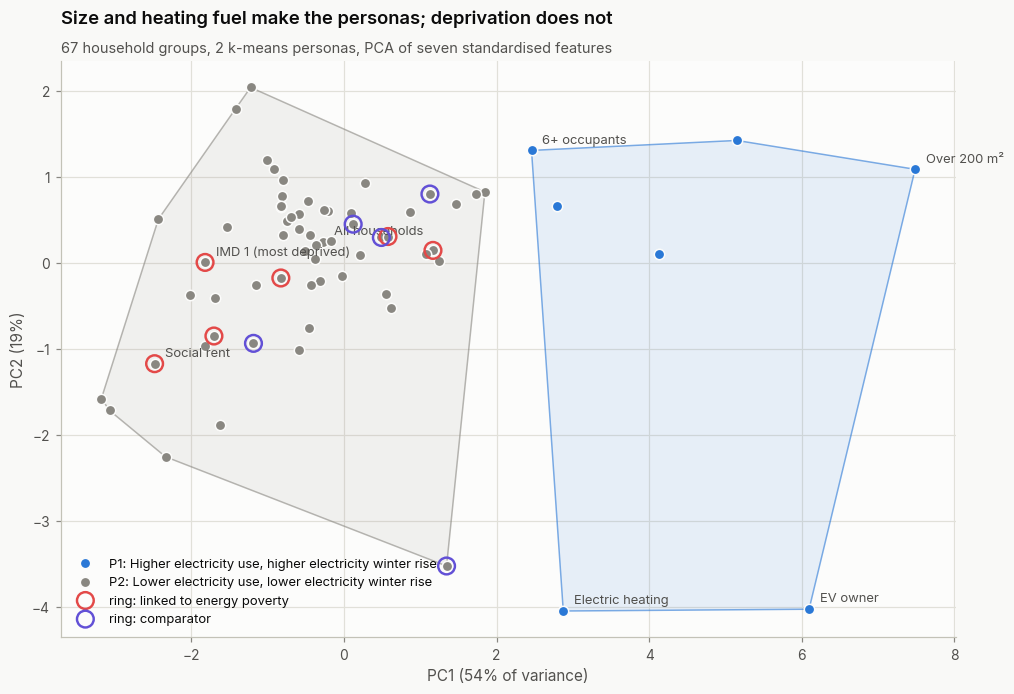

In [4]:
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA

pcs = PCA(2, random_state=42).fit(Z)
xy = pd.DataFrame(pcs.transform(Z), index=Z.index, columns=["pc1", "pc2"])
fig, ax = plt.subplots(figsize=(10.5, 6.8))
for c in order:
    pts = xy[labels == c].to_numpy()
    if len(pts) >= 3:
        hull = ConvexHull(pts)
        ax.fill(*pts[hull.vertices].T, color=persona_color[c], alpha=0.10, lw=0)
        ax.plot(*np.vstack([pts[hull.vertices], pts[hull.vertices][:1]]).T, color=persona_color[c], lw=1, alpha=0.6)
    ax.scatter(pts[:, 0], pts[:, 1], s=46, color=persona_color[c], edgecolor=COLORS["surface"], linewidth=1, zorder=3,
               label=names[c])
for r in ("vulnerable", "comparator"):
    sel = personas.set_index("group_label")["role"].eq(r).reindex(xy.index)
    ax.scatter(xy.loc[sel, "pc1"], xy.loc[sel, "pc2"], s=120, facecolor="none", edgecolor=ROLE_COLORS[r], lw=1.6,
               zorder=4, label="ring: linked to energy poverty" if r == "vulnerable" else "ring: comparator")
for g in ["All households", "Electric heating", "Over 200 m²", "EV owner", "IMD 1 (most deprived)", "Social rent",
          "Electric storage radiators", "6+ occupants"]:
    if g in xy.index:
        ax.annotate(g, xy.loc[g], xytext=(7, 5), textcoords="offset points", fontsize=8.5, color=INK["secondary"])
ax.set_xlabel(f"PC1 ({100 * pcs.explained_variance_ratio_[0]:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({100 * pcs.explained_variance_ratio_[1]:.0f}%)")
ax.legend(loc="lower left", fontsize=8.5)
plots.title(ax, "Size and heating fuel make the personas; deprivation does not",
            f"{len(Z)} household groups, {k} k-means personas, PCA of seven standardised features")
reporter.save_fig(fig, "persona-map")
plt.show()

**Persona profiles.** Each spoke is one feature, in standard deviations from the average group (the dashed ring is the average). **Look for:** the high-use persona is larger on every level feature and on the electricity winter rise, but has a lower evening-peak share and a smaller cut since 2020.


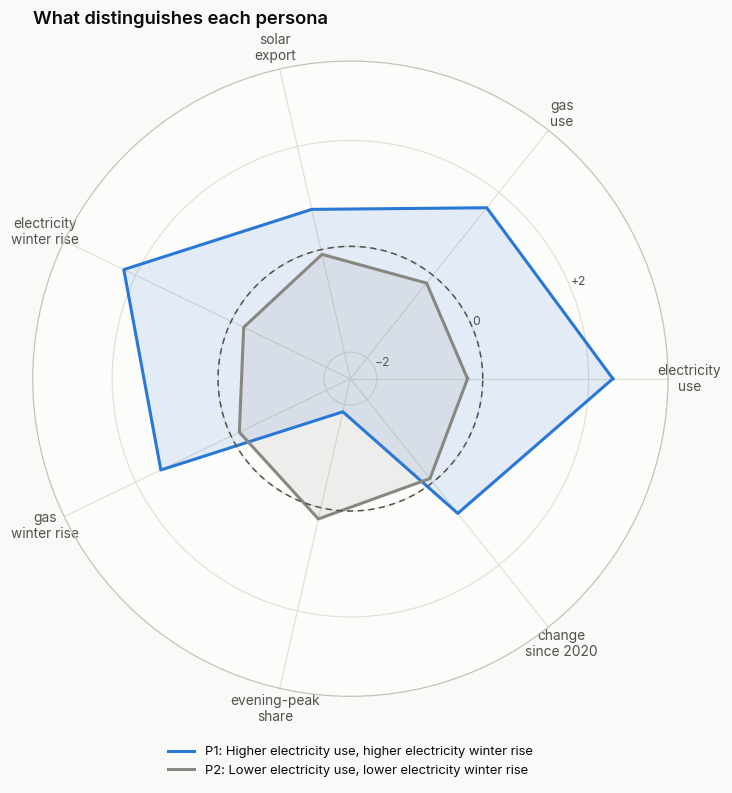

In [5]:
angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False)
fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw={"projection": "polar"})
lo = -2.5
for c in order:
    v = np.clip(centre_z.loc[c, FEATURES].to_numpy(), lo, None)
    ax.plot(np.append(angles, angles[0]), np.append(v, v[0]), color=persona_color[c], lw=2, label=names[c])
    ax.fill(np.append(angles, angles[0]), np.append(v, v[0]), color=persona_color[c], alpha=0.12)
ax.plot(np.linspace(0, 2 * np.pi, 200), np.zeros(200), color=INK["secondary"], lw=1, ls=(0, (4, 3)))
ax.set_xticks(angles, [SHORT[f].replace(" ", "\n", 1) for f in FEATURES], fontsize=9)
ax.set_ylim(lo, max(3.5, centre_z.to_numpy().max() + 0.3)); ax.set_yticks([-2, 0, 2], ["−2", "0", "+2"], fontsize=8)
ax.spines["polar"].set_color(COLORS["axis"])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=8.5)
ax.set_title("What distinguishes each persona", loc="left", pad=24, fontsize=12)
reporter.save_fig(fig, "persona-radar")
plt.show()

## Conclusions

- **Two personas, not more.** With only well-sampled groups kept, the silhouette score clearly favours k = 2 (0.57 vs ≤ 0.31 for larger k).
- **High-use, winter-peaking persona:** larger households (over 150 m², 5+ occupants or bedrooms), EV owners and electric-heated homes. They use far more electricity, much more of it in winter, a smaller share at 16:00–19:00, and cut back less since 2020.
- **Everyone else**, including every region, tenure, EPC band and deprivation quintile, shares one typical profile. Deprivation changes *how much* energy a group uses, not its pattern, so it does not form a persona of its own: all six energy-poverty groups and all five comparators fall in the typical persona.
- **What the 50-household rule removed:** solar PV, rent-free homes and the individual electric heating systems (storage heaters, radiators) rest on 10–40 homes in some 2023 months. An earlier run without the rule gave the electric-heating systems a persona of their own, but on too few homes to trust (see 1.2 for the 2021 PV profile).

## Limitations

- Groups overlap (a household belongs to several groups), so the groups are not independent and personas describe group averages, not households.
- Seven features on about 70 groups: personas are descriptive, and k is chosen within a narrow range of silhouette scores.
